In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv('BVBRC_genome_amr.csv')
df.shape

C:\Users\HP\AppData\Local\Temp\ipykernel_19980\2503448797.py:3: DtypeWarning: Columns (19,20) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('BVBRC_genome_amr.csv')


(171000, 21)

In [2]:
df = df.dropna(subset=['Resistant Phenotype'])
df = df[df['Resistant Phenotype'].isin(['Resistant','Susceptible'])]
print(df['Resistant Phenotype'].value_counts())

Resistant Phenotype
Susceptible    57912
Resistant      25183
Name: count, dtype: int64


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 83095 entries, 0 to 170998
Data columns (total 21 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Taxon ID                          83095 non-null  int64  
 1   Genome ID                         83095 non-null  float64
 2   Genome Name                       83095 non-null  object 
 3   Antibiotic                        83095 non-null  object 
 4   Resistant Phenotype               83095 non-null  object 
 5   Measurement                       704 non-null    object 
 6   Measurement Sign                  567 non-null    object 
 7   Measurement Value                 705 non-null    object 
 8   Measurement Unit                  705 non-null    object 
 9   Laboratory Typing Method          3005 non-null   object 
 10  Laboratory Typing Method Version  9 non-null      object 
 11  Laboratory Typing Platform        1071 non-null   object 
 12  Vendor  

In [4]:
df.duplicated().sum()

np.int64(1)

In [5]:
df = df.drop_duplicates()

In [6]:
df['Resistant Phenotype'].value_counts()

Resistant Phenotype
Susceptible    57911
Resistant      25183
Name: count, dtype: int64

In [7]:
df['Resistant Phenotype'] = df['Resistant Phenotype'].map({
    'Resistant': 1,
    'Susceptible': 0
})

In [8]:
df.head()

,Taxon ID,Genome ID,Genome Name,Antibiotic,Resistant Phenotype,Measurement,Measurement Sign,Measurement Value,Measurement Unit,Laboratory Typing Method,...,Laboratory Typing Platform,Vendor,Testing Standard,Testing Standard Year,Computational Method,Computational Method Version,Computational Method Performance,Evidence,Source,PubMed
0,562,562.174730,Escherichia coli strain UMDUCS23,trimethoprim/sulfamethoxazole,0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.94, CI[0.94, 0.95]",Computational Method,NaN,NaN
4,562,562.226510,Escherichia coli O23:H16 strain ECO0238,tetracycline,1,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.93, CI[0.89, 0.97]",Computational Method,NaN,NaN
5,562,562.289760,Escherichia coli strain 36549,cefalothin,0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.92, CI[0.89, 0.96]",Computational Method,NaN,NaN
6,562,562.179203,Escherichia coli PNUSAE020616,norfloxacin,0,NaN,NaN,NaN,NaN,NaN,...,NaN,BVBRC,NaN,NaN,SIR XGBoost Model,20250225.0,"F1 score: 0.96, CI[0.92, 1.01]",Computational Method,NaN,NaN
8,562,562.467480,Escherichia coli strain 113,doxycycline,1,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.87, CI[0.80, 0.95]",Computational Method,NaN,NaN


In [9]:
df['Resistant Phenotype'].value_counts()

Resistant Phenotype
0    57911
1    25183
Name: count, dtype: int64

In [10]:
df.isnull().sum()

Taxon ID                                0
Genome ID                               0
Genome Name                             0
Antibiotic                              0
Resistant Phenotype                     0
Measurement                         82390
Measurement Sign                    82527
Measurement Value                   82389
Measurement Unit                    82389
Laboratory Typing Method            80090
Laboratory Typing Method Version    83085
Laboratory Typing Platform          82024
Vendor                              65711
Testing Standard                    81096
Testing Standard Year               82527
Computational Method                 3099
Computational Method Version         3099
Computational Method Performance     3099
Evidence                               86
Source                              83094
PubMed                              81293
dtype: int64

In [11]:
df.shape

(83094, 21)

In [12]:
df.corr(numeric_only = True)

,Taxon ID,Genome ID,Resistant Phenotype,Testing Standard Year,Computational Method Version
Taxon ID,1.000000,0.992201,-0.054047,NaN,0.099944
Genome ID,0.992201,1.000000,-0.053336,-0.028578,0.099208
Resistant Phenotype,-0.054047,-0.053336,1.000000,-0.170301,0.072773
Testing Standard Year,NaN,-0.028578,-0.170301,1.000000,NaN
Computational Method Version,0.099944,0.099208,0.072773,NaN,1.000000


<Axes: >

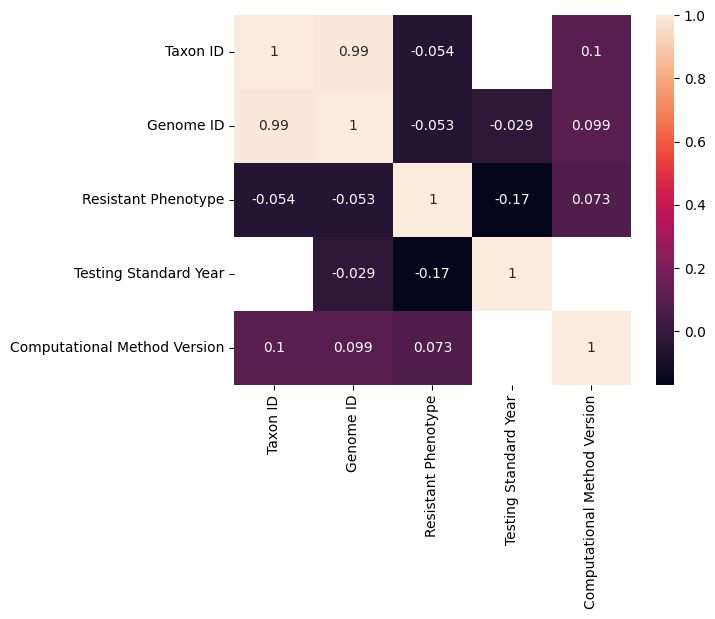

In [13]:
import seaborn as sns
sns.heatmap(df.corr(numeric_only = True),annot = True)

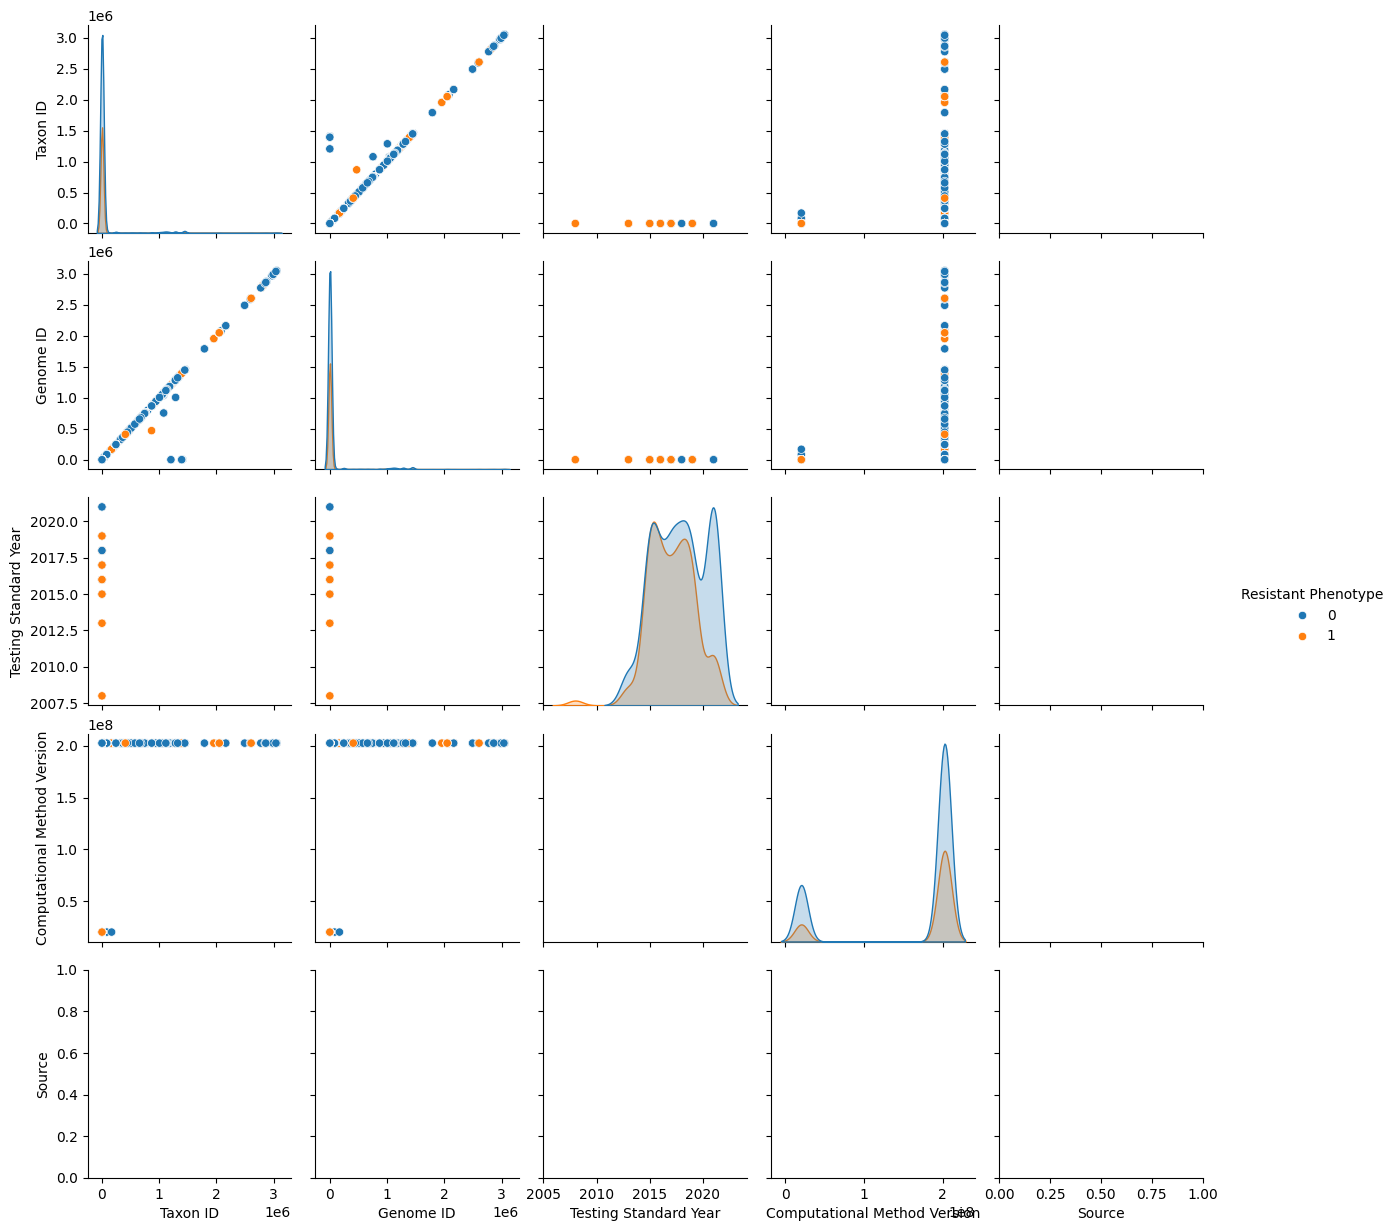

In [14]:
sns.pairplot(df,hue='Resistant Phenotype')

In [15]:
df['Genome Name'].value_counts().head(20)

Genome Name
Escherichia coli strain Fecal samples        476
Escherichia coli Fecal samples               162
Escherichia coli 131                         136
Escherichia coli                             115
Escherichia coli isolate                      82
Escherichia coli strain fhi                   68
Escherichia coli stool                        38
Escherichia coli str. K-12 substr. MG1655     31
Escherichia coli 10                           30
Escherichia coli blood                        29
Escherichia coli 69                           25
Escherichia coli 405                          24
Escherichia coli 117                          24
Escherichia coli 155                          19
Escherichia coli strain ST73                  18
Escherichia coli 101                          17
Escherichia coli strain E2                    17
Escherichia coli strain 131                   17
Escherichia coli strain 20                    17
Escherichia coli strain 10                    16
Name: co

In [16]:
df[df['Genome Name'] == 'Escherichia coli strain Fecal samples']['Resistant Phenotype'].mean()

np.float64(0.10504201680672269)

In [17]:
df[df['Genome Name'] == 'Escherichia coli Fecal samples']['Resistant Phenotype'].mean()

np.float64(0.09876543209876543)

In [18]:
df[df['Genome Name'] == 'Escherichia coli 131']['Resistant Phenotype'].mean() 

np.float64(0.5882352941176471)

In [19]:
df[df['Genome Name'] == 'Escherichia coli']['Resistant Phenotype'].mean() 

np.float64(0.1826086956521739)

In [20]:
genomes = [
    'Escherichia coli strain Fecal samples',
    'Escherichia coli Fecal samples',
    'Escherichia coli 131',
    'Escherichia coli',
    'Escherichia coli isolate',
    'Escherichia coli strain fhi',
    'Escherichia coli stool',
    'Escherichia coli str. K-12 substr. MG1655',
    'Escherichia coli 10',
    'Escherichia coli blood',
    'Escherichia coli 69',
    'Escherichia coli 405',
    'Escherichia coli 117',
    'Escherichia coli 155',
    'Escherichia coli strain ST73',
    'Escherichia coli 101',
    'Escherichia coli strain E2',
    'Escherichia coli strain 131',
    'Escherichia coli strain 20',
    'Escherichia coli strain 10'
]

for g in genomes:
    mean_val = df[df['Genome Name'] == g]['Resistant Phenotype'].mean()
    print(f"{g}: {mean_val:.4f}")

Escherichia coli strain Fecal samples: 0.1050
Escherichia coli Fecal samples: 0.0988
Escherichia coli 131: 0.5882
Escherichia coli: 0.1826
Escherichia coli isolate: 0.4268
Escherichia coli strain fhi: 0.0735
Escherichia coli stool: 0.3947
Escherichia coli str. K-12 substr. MG1655: 0.0323
Escherichia coli 10: 0.4667
Escherichia coli blood: 0.3103
Escherichia coli 69: 0.3200
Escherichia coli 405: 0.7500
Escherichia coli 117: 0.1667
Escherichia coli 155: 0.3684
Escherichia coli strain ST73: 0.1667
Escherichia coli 101: 0.2353
Escherichia coli strain E2: 0.6471
Escherichia coli strain 131: 0.5294
Escherichia coli strain 20: 0.4118
Escherichia coli strain 10: 0.3750


In [21]:
print(df['Antibiotic'].describe())

count          83094
unique            69
top       cefotaxime
freq            2927
Name: Antibiotic, dtype: object


In [22]:
antibiotics = [
    'cefotaxime', 'ciprofloxacin', 'ampicillin', 'ceftazidime',
    'meropenem', 'tobramycin', 'tetracycline', 'sulfamethoxazole',
    'aztreonam', 'chloramphenicol', 'doxycycline', 'nalidixic acid',
    'imipenem', 'amoxicillin', 'cefoxitin', 'cefazolin',
    'ertapenem', 'cefepime', 'norfloxacin', 'streptomycin',
    'ceftiofur', 'levofloxacin', 'ceftriaxone', 'gentamicin',
    'piperacillin/tazobactam', 'trimethoprim/sulfamethoxazole',
    'cefuroxime', 'amoxicillin/clavulanic acid',
    'ampicillin/sulbactam', 'trimethoprim', 'cefalothin',
    'trimotheprim', 'co_trimoxazole', 'ampicillin_clavulanic_acid',
    'cefuroxime_sodium', 'tazobactam_piperacillin',
    'amipicillin_sulbactam', 'geamycin', 'cephalothin', 'tigecycline'
]

result = (
    df[df['Antibiotic'].isin(antibiotics)]
    .groupby('Antibiotic')['Resistant Phenotype']
    .agg(['count', 'mean'])
    .sort_values(by='mean', ascending=False)
)

print(result)

                               count      mean
Antibiotic                                    
streptomycin                    2561  0.590004
doxycycline                     2651  0.557525
ampicillin                      2803  0.552265
amoxicillin                     2628  0.551750
sulfamethoxazole                2679  0.488988
trimethoprim                    2042  0.486288
trimethoprim/sulfamethoxazole   2248  0.467972
tetracycline                    2686  0.463142
nalidixic acid                  2634  0.392559
cefuroxime                      2230  0.372197
norfloxacin                     2568  0.368769
amoxicillin/clavulanic acid     2226  0.349057
cefalothin                      2004  0.339820
trimotheprim                     545  0.335780
co_trimoxazole                   544  0.321691
cefotaxime                      2927  0.310899
ceftriaxone                     2468  0.309562
levofloxacin                    2499  0.308924
ceftazidime                     2767  0.305385
cefazolin    

In [23]:
df[df['Antibiotic'].str.startswith('amoxicillin', na=False)]['Antibiotic'].unique()

array(['amoxicillin', 'amoxicillin/clavulanic acid',
       'amoxicillin-clavulanic acid'], dtype=object)

In [24]:
print(df['Vendor'].describe())

count     17383
unique        9
top       BVBRC
freq      16231
Name: Vendor, dtype: object


In [25]:
df['Vendor'].value_counts().head(20)

Vendor
BVBRC                       16231
BioMerieux                    886
Hardy Diagnostics             132
Thermo Fisher Scientific       64
Oxoid                          37
BD                             20
Interscience                    6
Trek Diagnostic Systems         6
Siemens                         1
Name: count, dtype: int64

In [26]:
df[df['Vendor'] == 'BVBRC']['Resistant Phenotype'].mean()

np.float64(0.2389255129073994)

In [27]:
df[df['Vendor'] == 'BioMerieux']['Resistant Phenotype'].mean()

np.float64(0.2708803611738149)

In [28]:
print(df['Evidence'].describe())

count                    83008
unique                       2
top       Computational Method
freq                     79995
Name: Evidence, dtype: object


In [29]:
print(df['Genome Name'].describe())

count                                     83094
unique                                    47394
top       Escherichia coli strain Fecal samples
freq                                        476
Name: Genome Name, dtype: object


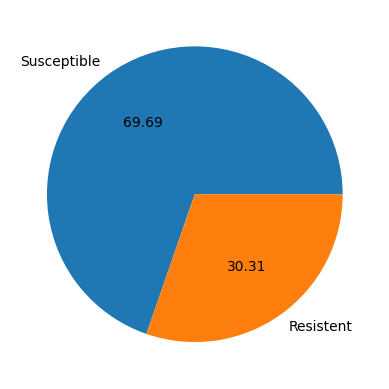

In [32]:
import matplotlib.pyplot as plt
plt.pie(df['Resistant Phenotype'].value_counts(),labels=['Susceptible','Resistent'],autopct="%0.2f")
plt.show()

In [33]:
df['Resistant Phenotype'].value_counts()

Resistant Phenotype
0    57911
1    25183
Name: count, dtype: int64

<Axes: xlabel='Antibiotic', ylabel='Count'>

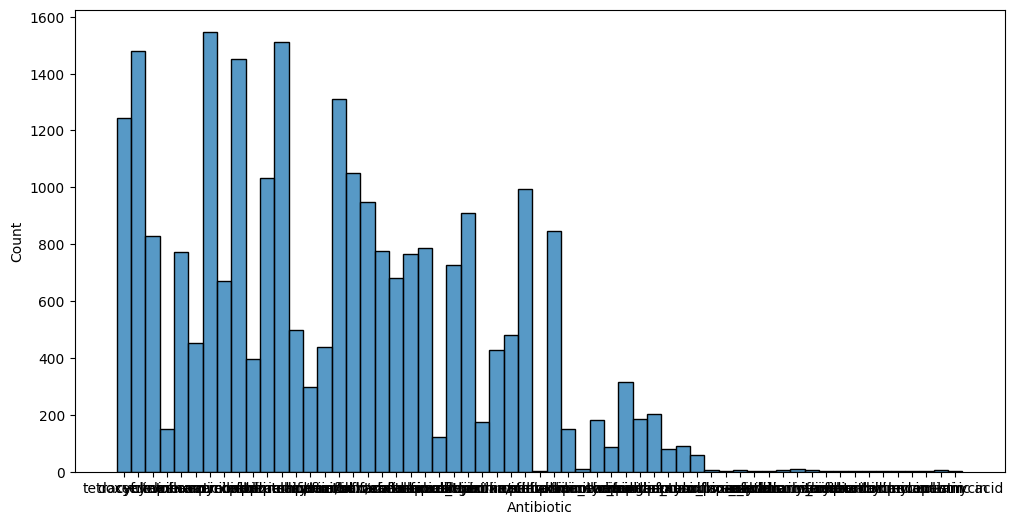

In [36]:
plt.figure(figsize=(12,6))
sns.histplot(df[df['Resistant Phenotype']==1]['Antibiotic'])

In [42]:
# Create the new column by removing "Escherichia coli" prefix cleanly
df['Species'] = df['Genome Name'].str.replace(
    r'^(Escherichia coli\s*)', '', 
    regex=True, 
    case=False
).str.strip()


# Handle completely empty cases (when Genome Name was only "Escherichia coli")
df['Species'] = df['Species'].replace('', 'Escherichia coli')

print("\nUnique values in 'Species' column (top 20):")
print(df['Species'].value_counts().head(20))

print("\nNumber of empty Species after cleaning:", (df['Species'] == '').sum())


Unique values in 'Species' column (top 20):
Species
strain Fecal samples        476
Fecal samples               162
131                         136
Escherichia coli            115
isolate                      82
strain fhi                   68
stool                        38
str. K-12 substr. MG1655     31
10                           30
blood                        29
69                           25
405                          24
117                          24
155                          19
strain ST73                  18
101                          17
strain E2                    17
strain 131                   17
strain 20                    17
strain 10                    16
Name: count, dtype: int64

Number of empty Species after cleaning: 0


In [43]:
df.head()

,Taxon ID,Genome ID,Genome Name,Antibiotic,Resistant Phenotype,Measurement,Measurement Sign,Measurement Value,Measurement Unit,Laboratory Typing Method,...,Testing Standard Year,Computational Method,Computational Method Version,Computational Method Performance,Evidence,Source,PubMed,Genus,Clean_Strain,Species
0,562,562.174730,Escherichia coli strain UMDUCS23,trimethoprim/sulfamethoxazole,0,NaN,NaN,NaN,NaN,NaN,...,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.94, CI[0.94, 0.95]",Computational Method,NaN,NaN,strain UMDUCS23,strain UMDUCS23,strain UMDUCS23
4,562,562.226510,Escherichia coli O23:H16 strain ECO0238,tetracycline,1,NaN,NaN,NaN,NaN,NaN,...,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.93, CI[0.89, 0.97]",Computational Method,NaN,NaN,O23:H16 strain ECO0238,O23:H16 strain ECO0238,O23:H16 strain ECO0238
5,562,562.289760,Escherichia coli strain 36549,cefalothin,0,NaN,NaN,NaN,NaN,NaN,...,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.92, CI[0.89, 0.96]",Computational Method,NaN,NaN,strain 36549,strain 36549,strain 36549
6,562,562.179203,Escherichia coli PNUSAE020616,norfloxacin,0,NaN,NaN,NaN,NaN,NaN,...,NaN,SIR XGBoost Model,20250225.0,"F1 score: 0.96, CI[0.92, 1.01]",Computational Method,NaN,NaN,PNUSAE020616,PNUSAE020616,PNUSAE020616
8,562,562.467480,Escherichia coli strain 113,doxycycline,1,NaN,NaN,NaN,NaN,NaN,...,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.87, CI[0.80, 0.95]",Computational Method,NaN,NaN,strain 113,strain 113,strain 113


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 83094 entries, 0 to 170998
Data columns (total 24 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Taxon ID                          83094 non-null  int64  
 1   Genome ID                         83094 non-null  float64
 2   Genome Name                       83094 non-null  object 
 3   Antibiotic                        83094 non-null  object 
 4   Resistant Phenotype               83094 non-null  int64  
 5   Measurement                       704 non-null    object 
 6   Measurement Sign                  567 non-null    object 
 7   Measurement Value                 705 non-null    object 
 8   Measurement Unit                  705 non-null    object 
 9   Laboratory Typing Method          3004 non-null   object 
 10  Laboratory Typing Method Version  9 non-null      object 
 11  Laboratory Typing Platform        1070 non-null   object 
 12  Vendor  

In [48]:
df1 = df[['Genome Name', 'Species', 'Antibiotic', 'Resistant Phenotype']].copy()

# Optional: Rename Resistant Phenotype to Target for clarity (recommended)
df1 = df1.rename(columns={'Resistant Phenotype': 'Target'})

print("Final shape:", df1.shape)
print("\nFinal columns:")
print(df1.columns.tolist())
print("\nFirst 10 rows:")
print(df1.head(10))

# Save the cleaned version (optional but good practice)
df1.to_csv('cleaned_dataset_for_model.csv', index=False)

Final shape: (83094, 4)

Final columns:
['Genome Name', 'Species', 'Antibiotic', 'Target']

First 10 rows:
                                Genome Name                 Species  \
0          Escherichia coli strain UMDUCS23         strain UMDUCS23   
4   Escherichia coli O23:H16 strain ECO0238  O23:H16 strain ECO0238   
5             Escherichia coli strain 36549            strain 36549   
6             Escherichia coli PNUSAE020616            PNUSAE020616   
8               Escherichia coli strain 113              strain 113   
9             Escherichia coli strain HS2-1            strain HS2-1   
10         Escherichia coli strain FAM21845         strain FAM21845   
12        Escherichia coli strain Ec-HUCA 5        strain Ec-HUCA 5   
14                   Escherichia coli GP188                   GP188   
16               Escherichia coli PT_EC0144               PT_EC0144   

                       Antibiotic  Target  
0   trimethoprim/sulfamethoxazole       0  
4                    te

In [54]:
df1.to_csv('dataset_for_model.csv', index=False)

In [72]:
df1 = pd.read_csv('dataset_for_model.csv')
df1.shape

(83094, 4)

In [73]:
df1.head()

,Genome Name,Species,Antibiotic,Target
0,Escherichia coli strain UMDUCS23,strain UMDUCS23,trimethoprim/sulfamethoxazole,0
1,Escherichia coli O23:H16 strain ECO0238,O23:H16 strain ECO0238,tetracycline,1
2,Escherichia coli strain 36549,strain 36549,cefalothin,0
3,Escherichia coli PNUSAE020616,PNUSAE020616,norfloxacin,0
4,Escherichia coli strain 113,strain 113,doxycycline,1


In [74]:
df1['Species'] = df1['Species'].replace('Escherichia coli ', 'Escherichia coli')

In [81]:
df1['Species'] = df1['Species'].replace({'\'Escherichia coli \'': 'Escherichia coli'})

In [82]:
df1.iloc[2592]

Genome Name    'Escherichia coli '
Species           Escherichia coli
Antibiotic        sulfamethoxazole
Target                           1
Name: 2592, dtype: object

In [90]:
df1['Genus']= df['Species'].copy()

In [93]:
df['Species'].describe()

count                    83094
unique                   47393
top       strain Fecal samples
freq                       476
Name: Species, dtype: object

In [92]:
df1['Genus'].describe()

count                    40260
unique                   29558
top       strain Fecal samples
freq                       225
Name: Genus, dtype: object

In [99]:
df.head()

,Taxon ID,Genome ID,Genome Name,Antibiotic,Resistant Phenotype,Measurement,Measurement Sign,Measurement Value,Measurement Unit,Laboratory Typing Method,...,Testing Standard Year,Computational Method,Computational Method Version,Computational Method Performance,Evidence,Source,PubMed,Genus,Clean_Strain,Species
0,562,562.174730,Escherichia coli strain UMDUCS23,trimethoprim/sulfamethoxazole,0,NaN,NaN,NaN,NaN,NaN,...,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.94, CI[0.94, 0.95]",Computational Method,NaN,NaN,strain UMDUCS23,strain UMDUCS23,strain UMDUCS23
4,562,562.226510,Escherichia coli O23:H16 strain ECO0238,tetracycline,1,NaN,NaN,NaN,NaN,NaN,...,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.93, CI[0.89, 0.97]",Computational Method,NaN,NaN,O23:H16 strain ECO0238,O23:H16 strain ECO0238,O23:H16 strain ECO0238
5,562,562.289760,Escherichia coli strain 36549,cefalothin,0,NaN,NaN,NaN,NaN,NaN,...,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.92, CI[0.89, 0.96]",Computational Method,NaN,NaN,strain 36549,strain 36549,strain 36549
6,562,562.179203,Escherichia coli PNUSAE020616,norfloxacin,0,NaN,NaN,NaN,NaN,NaN,...,NaN,SIR XGBoost Model,20250225.0,"F1 score: 0.96, CI[0.92, 1.01]",Computational Method,NaN,NaN,PNUSAE020616,PNUSAE020616,PNUSAE020616
8,562,562.467480,Escherichia coli strain 113,doxycycline,1,NaN,NaN,NaN,NaN,NaN,...,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.87, CI[0.80, 0.95]",Computational Method,NaN,NaN,strain 113,strain 113,strain 113


In [105]:
df2 = df[['Genome Name', 'Species', 'Antibiotic', 'Resistant Phenotype']].copy()

# Optional: Rename Resistant Phenotype to Target for clarity (recommended)
df2 = df2.rename(columns={'Resistant Phenotype': 'Target'})

print("Final shape:", df2.shape)
print("\nFinal columns:")
print(df2.columns.tolist())
print("\nFirst 10 rows:")
print(df2.head(10))

# Save the cleaned version (optional but good practice)
df2.to_csv('dataset-2_for_model.csv', index=False)

Final shape: (83094, 4)

Final columns:
['Genome Name', 'Species', 'Antibiotic', 'Target']

First 10 rows:
                                Genome Name                 Species  \
0          Escherichia coli strain UMDUCS23         strain UMDUCS23   
4   Escherichia coli O23:H16 strain ECO0238  O23:H16 strain ECO0238   
5             Escherichia coli strain 36549            strain 36549   
6             Escherichia coli PNUSAE020616            PNUSAE020616   
8               Escherichia coli strain 113              strain 113   
9             Escherichia coli strain HS2-1            strain HS2-1   
10         Escherichia coli strain FAM21845         strain FAM21845   
12        Escherichia coli strain Ec-HUCA 5        strain Ec-HUCA 5   
14                   Escherichia coli GP188                   GP188   
16               Escherichia coli PT_EC0144               PT_EC0144   

                       Antibiotic  Target  
0   trimethoprim/sulfamethoxazole       0  
4                    te

In [106]:
df2 = pd.read_csv('dataset-2_for_model.csv')
df2.shape

(83094, 4)

In [107]:
df2['Species'].describe()

count                    83094
unique                   47393
top       strain Fecal samples
freq                       476
Name: Species, dtype: object

In [104]:
df['Species'].describe()

count                    83094
unique                   47393
top       strain Fecal samples
freq                       476
Name: Species, dtype: object

In [108]:
import pandas as pd
import re

def map_species_categories(df, species_col='Species'):
    """
    Map redundant species categories to meaningful, unique categories.
    
    Parameters:
    -----------
    df : pandas DataFrame
        The dataframe containing the species column
    species_col : str
        The name of the column containing species information
    
    Returns:
    --------
    df : pandas DataFrame
        The dataframe with a new column 'Species_Mapped' containing the mapped categories
    mapping_dict : dict
        Dictionary showing the mapping from original to new categories
    """
    
    # Create a copy to avoid modifying the original
    df = df.copy()
    
    # Initialize the new column with original values
    df['Species_Mapped'] = df[species_col].astype(str)
    
    # Create a mapping dictionary for tracking
    mapping_dict = {}
    
    # Define mapping rules in order of priority
    # More specific patterns should come first
    
    mapping_rules = [
        # Clinical sources
        (r'(?i)^.*\bblood\b.*$', 'Blood'),
        (r'(?i)^.*\burine\b.*$', 'Urine'),
        (r'(?i)^.*\bstool\b.*$', 'Stool/Fecal'),
        (r'(?i)^.*\bfecal\b.*$', 'Stool/Fecal'),
        (r'(?i)^.*\bstool\b.*$', 'Stool/Fecal'),
        (r'(?i)^.*\bsputum\b.*$', 'Sputum/Respiratory'),
        (r'(?i)^.*\brespiratory\b.*$', 'Sputum/Respiratory'),
        (r'(?i)^.*\bwound\b.*$', 'Wound'),
        (r'(?i)^.*\babscess\b.*$', 'Abscess'),
        
        # Animal sources
        (r'(?i)^.*\bcattle\b.*$', 'Bovine/Cattle'),
        (r'(?i)^.*\bbovine\b.*$', 'Bovine/Cattle'),
        (r'(?i)^.*\bswine\b.*$', 'Porcine/Swine'),
        (r'(?i)^.*\bporcine\b.*$', 'Porcine/Swine'),
        (r'(?i)^.*\bpig\b.*$', 'Porcine/Swine'),
        (r'(?i)^.*\bpoultry\b.*$', 'Poultry/Chicken'),
        (r'(?i)^.*\bchicken\b.*$', 'Poultry/Chicken'),
        (r'(?i)^.*\bbroiler\b.*$', 'Poultry/Chicken'),
        (r'(?i)^.*\bsheep\b.*$', 'Ovine/Sheep'),
        (r'(?i)^.*\bovine\b.*$', 'Ovine/Sheep'),
        (r'(?i)^.*\bhorse\b.*$', 'Equine/Horse'),
        (r'(?i)^.*\bcanine\b.*$', 'Canine/Dog'),
        (r'(?i)^.*\bfeline\b.*$', 'Feline/Cat'),
        
        # Specific strain collections (in order of specificity)
        (r'(?i)^.*\bstrain\s+FDAARGOS[_ ]*', 'FDAARGOS Isolate'),
        (r'(?i)^.*\bFDAARGOS[_ ]*', 'FDAARGOS Isolate'),
        (r'(?i)^.*\bstrain\s+ATCC\s*\d+', 'ATCC Isolate'),
        (r'(?i)^.*\bATCC\s*\d+', 'ATCC Isolate'),
        (r'(?i)^.*\bstrain\s+NCTC\s*\d+', 'NCTC Isolate'),
        (r'(?i)^.*\bNCTC\s*\d+', 'NCTC Isolate'),
        (r'(?i)^.*\bstrain\s+PNUSAE\w+', 'PNUSAE Isolate'),
        (r'(?i)^.*\bPNUSAE\w+', 'PNUSAE Isolate'),
        (r'(?i)^.*\bstrain\s+MOD1-EC\w+', 'MOD1-EC Isolate'),
        (r'(?i)^.*\bMOD1-EC\w+', 'MOD1-EC Isolate'),
        (r'(?i)^.*\bstrain\s+UMDUCS\w+', 'UMDUCS/CD Isolate'),
        (r'(?i)^.*\bUMDUCS\w+', 'UMDUCS/CD Isolate'),
        (r'(?i)^.*\bUMDUCD', 'UMDUCS/CD Isolate'),
        (r'(?i)^.*\bstrain\s+KCJ\w+', 'KCJ Isolate'),
        (r'(?i)^.*\bKCJ\w+', 'KCJ Isolate'),
        (r'(?i)^.*\bstrain\s+VREC\w+', 'VREC Isolate'),
        (r'(?i)^.*\bVREC\w+', 'VREC Isolate'),
        (r'(?i)^.*\bstrain\s+VRES\w+', 'VRES Isolate'),
        (r'(?i)^.*\bVRES\w+', 'VRES Isolate'),
        (r'(?i)^.*\bstrain\s+JB\w+', 'JB Isolate'),
        (r'(?i)^.*\bJB[A-Z]{6}-\d+', 'JB Isolate'),
        (r'(?i)^.*\bstrain\s+[A-Z]{2,3}EC\w+', 'EC Isolate'),
        (r'(?i)^.*\bEC[A-Z0-9]+\b', 'EC Isolate'),
        
        # Laboratory strains
        (r'(?i)^.*\bK-12\b.*$', 'K-12 Laboratory Strain'),
        (r'(?i)^.*\bMG1655\b.*$', 'MG1655 Laboratory Strain'),
        (r'(?i)^.*\bDH5[αa]lpha\b.*$', 'DH5α Laboratory Strain'),
        (r'(?i)^.*\bBL21\b.*$', 'BL21 Laboratory Strain'),
        (r'(?i)^.*\bJM109\b.*$', 'JM109 Laboratory Strain'),
        
        # Reference strains
        (r'(?i)^.*\breference\s+strain\b.*$', 'Reference Strain'),
        (r'(?i)^.*\btype\s+strain\b.*$', 'Type Strain'),
        
        # O-antigen serotypes
        (r'(?i)^.*\bO\d+:[A-Z0-9]+\b.*$', 'O-Antigen Serotype'),
        (r'(?i)^.*\bO\d+[A-Z]?\b.*$', 'O-Antigen Serotype'),
        
        # Isolate with numbers (catch-all for numbered isolates)
        (r'(?i)^.*\bisolate\s+\d+.*$', 'Numbered Isolate'),
        
        # Clinical isolates
        (r'(?i)^.*\bclinical\s+isolate\b.*$', 'Clinical Isolate'),
        (r'(?i)^.*\bpatient\b.*$', 'Clinical Isolate'),
        
        # Environmental sources
        (r'(?i)^.*\benvironmental\b.*$', 'Environmental Isolate'),
        (r'(?i)^.*\bwater\b.*$', 'Water Isolate'),
        (r'(?i)^.*\bsoil\b.*$', 'Soil Isolate'),
        
        # Food sources
        (r'(?i)^.*\bfood\b.*$', 'Food Isolate'),
        (r'(?i)^.*\bmeat\b.*$', 'Meat Isolate'),
        (r'(?i)^.*\bmilk\b.*$', 'Milk Isolate'),
        
        # Default patterns (should come last)
        (r'(?i)^.*\bstrain\s+[A-Za-z0-9-]+$', 'Named Strain'),
        (r'(?i)^.*\bstrain\s+\d+.*$', 'Numbered Strain'),
        (r'(?i)^.*\b\d+[A-Za-z]*-?\d*$', 'Numbered Isolate'),
        (r'(?i)^.*\b[A-Za-z]{2,}-\d+$', 'Alphanumeric Isolate'),
    ]
    
    # Apply mapping rules
    for pattern, category in mapping_rules:
        mask = df['Species_Mapped'].str.contains(pattern, case=False, na=False, regex=True)
        # Only apply to rows that haven't been mapped yet (still have original or non-mapped values)
        # We'll keep track of mapped rows by checking if they've been changed
        # For simplicity, we'll apply in order and overwrite - more specific rules first will win
        df.loc[mask, 'Species_Mapped'] = category
    
    # Special handling for "strain" prefix with numbers - catch any remaining "strain XXX" patterns
    strain_num_mask = df['Species_Mapped'].str.contains(r'^strain\s+\d+', case=False, na=False, regex=True)
    df.loc[strain_num_mask, 'Species_Mapped'] = 'Numbered Strain'
    
    # Handle empty/unknown
    df.loc[df['Species_Mapped'].str.strip() == '', 'Species_Mapped'] = 'Unknown'
    df.loc[df['Species_Mapped'].str.lower() == 'nan', 'Species_Mapped'] = 'Unknown'
    df.loc[df['Species_Mapped'].isna(), 'Species_Mapped'] = 'Unknown'
    
    # Create mapping dictionary for reference
    original_categories = df[species_col].unique()
    for orig in original_categories:
        mapped_value = df.loc[df[species_col] == orig, 'Species_Mapped'].iloc[0]
        mapping_dict[orig] = mapped_value
    
    # Print summary statistics
    print("=" * 60)
    print("Species Mapping Summary")
    print("=" * 60)
    print(f"Original unique categories: {df[species_col].nunique()}")
    print(f"Mapped unique categories: {df['Species_Mapped'].nunique()}")
    print("\nTop 20 mapped categories:")
    print(df['Species_Mapped'].value_counts().head(20))
    
    return df, mapping_dict


def analyze_species_patterns(df, species_col='Species'):
    """
    Analyze patterns in the species column to help refine mapping.
    
    Parameters:
    -----------
    df : pandas DataFrame
        The dataframe containing the species column
    species_col : str
        The name of the column containing species information
    """
    
    print("=" * 60)
    print("Species Column Pattern Analysis")
    print("=" * 60)
    
    # Get unique values
    unique_species = df[species_col].unique()
    
    # Define pattern groups to count
    patterns = {
        'Contains "blood"': r'blood',
        'Contains "urine"': r'urine',
        'Contains "stool" or "fecal"': r'stool|fecal',
        'Contains "cattle" or "bovine"': r'cattle|bovine',
        'Contains "swine" or "pig"': r'swine|pig',
        'Contains "chicken" or "poultry"': r'chicken|poultry|broiler',
        'Contains "sheep" or "ovine"': r'sheep|ovine',
        'Starts with "strain"': r'^strain',
        'Contains "EC" pattern': r'\bEC\d+',
        'Contains "MOD1-EC"': r'MOD1-EC',
        'Contains "PNUSAE"': r'PNUSAE',
        'Contains "ATCC"': r'ATCC',
        'Contains "NCTC"': r'NCTC',
        'Contains "FDAARGOS"': r'FDAARGOS',
        'Contains "KCJ"': r'KCJ',
        'Contains "VREC"': r'VREC',
        'Contains "VRES"': r'VRES',
        'Contains "JB" prefix': r'\bJB[A-Z]{5,}',
        'Contains "K-12"': r'K-12',
        'Contains "MG1655"': r'MG1655',
        'Contains "DH5"': r'DH5',
        'Contains "BL21"': r'BL21',
        'Contains "JM109"': r'JM109',
    }
    
    print("\nPattern Counts in Species Column:")
    for pattern_name, pattern_regex in patterns.items():
        count = df[species_col].str.contains(pattern_regex, case=False, na=False, regex=True).sum()
        print(f"  {pattern_name}: {count}")
    
    # Show some examples of unique values
    print("\nSample of unique species values (first 50):")
    for val in sorted(unique_species)[:50]:
        print(f"  {val}")
    
    return


def get_mapping_dict_from_mapping(df, species_col='Species', mapped_col='Species_Mapped'):
    """
    Get a dictionary mapping original species to mapped categories.
    
    Parameters:
    -----------
    df : pandas DataFrame
        The dataframe with mapping applied
    species_col : str
        Original species column name
    mapped_col : str
        Mapped species column name
    
    Returns:
    --------
    dict : Mapping from original to mapped categories
    """
    mapping_dict = {}
    unique_original = df[species_col].unique()
    for orig in unique_original:
        mapped = df.loc[df[species_col] == orig, mapped_col].iloc[0]
        mapping_dict[orig] = mapped
    return mapping_dict


# Example usage:
if __name__ == "__main__":
    # Assuming your dataframe is named df2
    # df2 = pd.read_csv('your_file.csv')  # Uncomment if reading from file
    
    # Analyze patterns first (optional)
    # analyze_species_patterns(df2, 'Species')
    
    # Apply mapping
    df2_mapped, mapping_dict = map_species_categories(df2, 'Species')
    
    # View the mapped column
    print("\n" + "=" * 60)
    print("Sample of mapped values:")
    print("=" * 60)
    sample_df = df2_mapped[['Species', 'Species_Mapped']].drop_duplicates().head(30)
    print(sample_df.to_string(index=False))
    
    # You can now use df2_mapped['Species_Mapped'] for your analysis

Species Mapping Summary
Original unique categories: 47393
Mapped unique categories: 14974

Top 20 mapped categories:
Species_Mapped
Named Strain              18361
Numbered Isolate          13800
PNUSAE Isolate             8857
EC Isolate                 6546
MOD1-EC Isolate            2558
O-Antigen Serotype         1843
Numbered Strain            1473
VREC Isolate               1292
Stool/Fecal                 676
KCJ Isolate                 568
VRES Isolate                543
NCTC Isolate                300
Blood                       154
K-12 Laboratory Strain      143
UMDUCS/CD Isolate           131
Escherichia coli            128
FDAARGOS Isolate            118
isolate                      82
ATCC Isolate                 81
Poultry/Chicken              52
Name: count, dtype: int64

Sample of mapped values:
                             Species                       Species_Mapped
                     strain UMDUCS23                    UMDUCS/CD Isolate
              O23:H16 strain

In [112]:
df2_mapped.shape

(83094, 5)

In [113]:
df2_mapped.head()

,Genome Name,Species,Antibiotic,Target,Species_Mapped
0,Escherichia coli strain UMDUCS23,strain UMDUCS23,trimethoprim/sulfamethoxazole,0,UMDUCS/CD Isolate
1,Escherichia coli O23:H16 strain ECO0238,O23:H16 strain ECO0238,tetracycline,1,EC Isolate
2,Escherichia coli strain 36549,strain 36549,cefalothin,0,Named Strain
3,Escherichia coli PNUSAE020616,PNUSAE020616,norfloxacin,0,PNUSAE Isolate
4,Escherichia coli strain 113,strain 113,doxycycline,1,Named Strain


In [116]:
df2_mapped['Species_Mapped'].describe()

count            83094
unique           14974
top       Named Strain
freq             18361
Name: Species_Mapped, dtype: object

In [130]:
df2.to_csv('dataset-7_for_model.csv', index=False)

In [118]:
import pandas as pd
import re

def map_species_categories_enhanced(df, species_col='Species'):
    """
    Enhanced mapping to reduce to ~500 unique categories.
    """
    df = df.copy()
    df['Species_Mapped'] = df[species_col].astype(str)
    
    # Track mapping for reference
    mapping_dict = {}
    
    # ==================== PART 1: SPECIFIC PATTERNS (HIGH PRIORITY) ====================
    
    # Clinical source patterns
    clinical_patterns = [
        (r'(?i)\b(blood|bloodstream|bacteremia|sepsis)\b', 'Clinical: Blood'),
        (r'(?i)\b(urine|urinary|uro|UTI)\b', 'Clinical: Urine'),
        (r'(?i)\b(stool|fecal|feces|diarrhea|rectal)\b', 'Clinical: Stool/Fecal'),
        (r'(?i)\b(sputum|respiratory|pulmonary|lung|broncho|tracheal)\b', 'Clinical: Respiratory'),
        (r'(?i)\b(wound|abscess|pus|purulent|surgical|post-op)\b', 'Clinical: Wound/Abscess'),
        (r'(?i)\b(CSF|cerebrospinal|meningitis|neurological)\b', 'Clinical: CSF'),
        (r'(?i)\b(skin|soft tissue|dermal|cells)\b', 'Clinical: Skin/Soft Tissue'),
        (r'(?i)\b(catheter|line|device|implant)\b', 'Clinical: Medical Device'),
        (r'(?i)\b(swab|specimen|isolate)\b', 'Clinical: General Specimen'),
    ]
    
    # Animal source patterns
    animal_patterns = [
        (r'(?i)\b(cattle|bovine|cow|calf)\b', 'Animal: Bovine/Cattle'),
        (r'(?i)\b(swine|pig|porcine|hog)\b', 'Animal: Porcine/Swine'),
        (r'(?i)\b(chicken|poultry|broiler|turkey|avian|fowl)\b', 'Animal: Poultry'),
        (r'(?i)\b(sheep|ovine|lamb|ram|ewe)\b', 'Animal: Ovine/Sheep'),
        (r'(?i)\b(horse|equine|foal)\b', 'Animal: Equine/Horse'),
        (r'(?i)\b(dog|canine|puppy)\b', 'Animal: Canine/Dog'),
        (r'(?i)\b(cat|feline|kitten)\b', 'Animal: Feline/Cat'),
        (r'(?i)\b(fish|aquatic|marine)\b', 'Animal: Fish/Aquatic'),
        (r'(?i)\b(wildlife|zoo|exotic)\b', 'Animal: Wildlife/Exotic'),
    ]
    
    # Environmental sources
    environmental_patterns = [
        (r'(?i)\b(water|aquatic|river|lake|pond|marine|sewage)\b', 'Environmental: Water'),
        (r'(?i)\b(soil|sediment|dirt|mud)\b', 'Environmental: Soil'),
        (r'(?i)\b(food|meat|milk|dairy|produce|vegetable|fruit|crop)\b', 'Environmental: Food'),
        (r'(?i)\b(farm|agriculture|manure|livestock|feedlot)\b', 'Environmental: Agricultural'),
        (r'(?i)\b(hospital|healthcare|clinic|medical)\b', 'Environmental: Healthcare'),
        (r'(?i)\b(community|household|home|domestic)\b', 'Environmental: Community'),
    ]
    
    # ==================== PART 2: STRAIN COLLECTIONS ====================
    
    # Major reference collections
    collection_patterns = [
        (r'(?i)ATCC\s*\d+', 'Collection: ATCC'),
        (r'(?i)NCTC\s*\d+', 'Collection: NCTC'),
        (r'(?i)CCUG\s*\d+', 'Collection: CCUG'),
        (r'(?i)DSM\s*\d+', 'Collection: DSMZ'),
        (r'(?i)JCM\s*\d+', 'Collection: JCM'),
        (r'(?i)CIP\s*\d+', 'Collection: CIP'),
        (r'(?i)FDAARGOS', 'Collection: FDA-ARGOS'),
        (r'(?i)PNUSAE\d+', 'Collection: CDC/PNUSAE'),
        (r'(?i)MOD1-EC\d+', 'Collection: MOD1-EC'),
        (r'(?i)UMDUCS?\d+', 'Collection: UMDUC'),
        (r'(?i)UMDUCD', 'Collection: UMDUC'),
        (r'(?i)KCJ\d+', 'Collection: KCJ'),
        (r'(?i)VREC\d+', 'Collection: VREC'),
        (r'(?i)VRES\d+', 'Collection: VRES'),
        (r'(?i)JB[A-Z]{5,}\d+', 'Collection: JBLab'),
        (r'(?i)MGL_\d+', 'Collection: MGL'),
        (r'(?i)MUWRP\d+', 'Collection: MUWRP'),
        (r'(?i)ERR\d+', 'Collection: ENA/SRA'),
        (r'(?i)SRR\d+', 'Collection: SRA'),
    ]
    
    # ==================== PART 3: LABORATORY STRAINS ====================
    
    lab_strain_patterns = [
        (r'(?i)K-12\b', 'Lab Strain: K-12'),
        (r'(?i)MG1655', 'Lab Strain: MG1655'),
        (r'(?i)DH5[αa]', 'Lab Strain: DH5α'),
        (r'(?i)BL21', 'Lab Strain: BL21'),
        (r'(?i)JM109', 'Lab Strain: JM109'),
        (r'(?i)HB101', 'Lab Strain: HB101'),
        (r'(?i)TOP10', 'Lab Strain: TOP10'),
        (r'(?i)BW25113', 'Lab Strain: BW25113'),
        (r'(?i)W3110', 'Lab Strain: W3110'),
        (r'(?i)CFT073', 'Lab Strain: CFT073'),
        (r'(?i)UTI89', 'Lab Strain: UTI89'),
        (r'(?i)Nissle\s*1917', 'Lab Strain: Nissle 1917'),
        (r'(?i)EDL933', 'Lab Strain: EDL933'),
        (r'(?i)O157:H7', 'Lab Strain: O157:H7 Reference'),
    ]
    
    # ==================== PART 4: SEROTYPE-BASED ====================
    
    serotype_patterns = [
        (r'(?i)O\d+:[A-Z0-9]+', 'Serotype: O:H Type'),
        (r'(?i)O\d+\w*', 'Serotype: O-Antigen'),
        (r'(?i)ST\d+', 'Sequence Type: ST'),
        (r'(?i)clonal\s+complex\s+\d+', 'Sequence Type: Clonal Complex'),
    ]
    
    # ==================== PART 5: COUNTRY/REGION ====================
    
    location_patterns = [
        (r'(?i)\b(USA|US|United States|American)\b', 'Location: USA'),
        (r'(?i)\b(UK|United Kingdom|England|Scotland|Wales)\b', 'Location: UK'),
        (r'(?i)\b(China|Chinese|Beijing|Shanghai)\b', 'Location: China'),
        (r'(?i)\b(Japan|Japanese|Tokyo|Osaka)\b', 'Location: Japan'),
        (r'(?i)\b(Korea|Korean|Seoul)\b', 'Location: Korea'),
        (r'(?i)\b(India|Indian|Mumbai|Delhi)\b', 'Location: India'),
        (r'(?i)\b(Brazil|Brazilian|Sao Paulo)\b', 'Location: Brazil'),
        (r'(?i)\b(Europe|European|France|Germany|Italy|Spain)\b', 'Location: Europe'),
        (r'(?i)\b(Australia|Australian)\b', 'Location: Australia'),
        (r'(?i)\b(Africa|African|Kenya|Nigeria|South Africa)\b', 'Location: Africa'),
        (r'(?i)\b(Middle East|UAE|Saudi|Qatar|Kuwait)\b', 'Location: Middle East'),
    ]
    
    # ==================== PART 6: SEQUENCE TYPE/GROUP ====================
    
    sequence_patterns = [
        (r'(?i)ST\d{2,3}\b', 'Sequence Type: ST'),
        (r'(?i)CC\d+', 'Sequence Type: Clonal Complex'),
        (r'(?i)B2\s+ST', 'Sequence Type: B2 ST'),
        (r'(?i)phylogroup\s+[A-D]', 'Phylogroup'),
    ]
    
    # ==================== PART 7: MISCELLANEOUS ====================
    
    misc_patterns = [
        (r'(?i)^strain\s+(\w+)$', r'Strain: \1'),  # Named strains
        (r'(?i)^strain\s+(\d+)$', 'Numbered Strain'),
        (r'(?i)^strain\s+([A-Z]+)$', r'Named Strain: \1'),
        (r'(?i)^\d+[A-Za-z]*-?\d+$', 'Numbered Isolate'),
        (r'(?i)^[A-Za-z]{2,}-\d+$', 'Alphanumeric Isolate'),
        (r'(?i)^[A-Z]{2,}\d+$', 'Alphanumeric Isolate'),
    ]
    
    # Combine all patterns in order of priority
    all_patterns = []
    all_patterns.extend(clinical_patterns)
    all_patterns.extend(animal_patterns)
    all_patterns.extend(environmental_patterns)
    all_patterns.extend(collection_patterns)
    all_patterns.extend(lab_strain_patterns)
    all_patterns.extend(serotype_patterns)
    all_patterns.extend(location_patterns)
    all_patterns.extend(sequence_patterns)
    all_patterns.extend(misc_patterns)
    
    # Apply patterns
    for pattern, category in all_patterns:
        mask = df['Species_Mapped'].str.contains(pattern, case=False, na=False, regex=True)
        df.loc[mask, 'Species_Mapped'] = category
    
    # ==================== PART 8: POST-PROCESSING ====================
    
    # Clean up "strain" prefix for remaining entries
    strain_mask = df['Species_Mapped'].str.contains(r'^strain\s+', case=False, na=False, regex=True)
    df.loc[strain_mask, 'Species_Mapped'] = df.loc[strain_mask, 'Species_Mapped'].str.replace(
        r'^strain\s+', '', regex=True
    )
    
    # Group by first word for remaining unique entries
    # This will catch all remaining patterns and group them by their first word
    first_word_mask = ~df['Species_Mapped'].isin([cat for _, cat in all_patterns])
    df.loc[first_word_mask, 'Species_Mapped'] = df.loc[first_word_mask, 'Species_Mapped'].apply(
        lambda x: f"Other: {x.split()[0]}" if x and len(x.split()) > 0 else "Other: Unknown"
    )
    
    # Handle empty/unknown
    df.loc[df['Species_Mapped'].str.strip() == '', 'Species_Mapped'] = 'Unknown'
    df.loc[df['Species_Mapped'].str.lower() == 'nan', 'Species_Mapped'] = 'Unknown'
    df.loc[df['Species_Mapped'].isna(), 'Species_Mapped'] = 'Unknown'
    
    # Further consolidate "Other" categories that are too granular
    other_mask = df['Species_Mapped'].str.startswith('Other:', na=False)
    other_counts = df.loc[other_mask, 'Species_Mapped'].value_counts()
    
    # Keep only Other categories with > 100 entries, group the rest
    for other_cat in other_counts[other_counts <= 100].index:
        df.loc[df['Species_Mapped'] == other_cat, 'Species_Mapped'] = 'Other: Rare'
    
    # Create mapping dictionary
    for orig in df[species_col].unique():
        mapped_value = df.loc[df[species_col] == orig, 'Species_Mapped'].iloc[0]
        mapping_dict[orig] = mapped_value
    
    # ==================== PART 9: PRINT SUMMARY ====================
    
    print("=" * 80)
    print("ENHANCED SPECIES MAPPING SUMMARY")
    print("=" * 80)
    print(f"Original unique categories: {df[species_col].nunique():,}")
    print(f"Mapped unique categories: {df['Species_Mapped'].nunique():,}")
    print(f"Reduction: {((df[species_col].nunique() - df['Species_Mapped'].nunique()) / df[species_col].nunique() * 100):.1f}%")
    
    print("\n" + "=" * 80)
    print("TOP 30 MAPPED CATEGORIES:")
    print("=" * 80)
    top_categories = df['Species_Mapped'].value_counts().head(30)
    for cat, count in top_categories.items():
        print(f"  {cat}: {count:,}")
    
    # Show examples of what's in "Other" categories
    print("\n" + "=" * 80)
    print("SAMPLE OF 'OTHER' CATEGORIES:")
    print("=" * 80)
    other_examples = df[df['Species_Mapped'].str.startswith('Other:', na=False)][species_col].value_counts().head(20)
    for ex in other_examples.index:
        print(f"  {ex}")
    
    return df, mapping_dict


# Apply the enhanced mapping
df2_mapped, mapping_dict = map_species_categories_enhanced(df2, 'Species')

# Add the mapped column back to original dataframe
df2['Species_Mapped'] = df2_mapped['Species_Mapped']

# Verify results
print("\n" + "=" * 80)
print("FINAL VERIFICATION:")
print("=" * 80)
print(f"Unique categories in Species_Mapped: {df2['Species_Mapped'].nunique():,}")
print(f"\nCategory distribution preview:")
print(df2['Species_Mapped'].value_counts().head(20))

C:\Users\HP\AppData\Local\Temp\ipykernel_19980\2195958508.py:155: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = df['Species_Mapped'].str.contains(pattern, case=False, na=False, regex=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_19980\2195958508.py:155: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = df['Species_Mapped'].str.contains(pattern, case=False, na=False, regex=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_19980\2195958508.py:155: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = df['Species_Mapped'].str.contains(pattern, case=False, na=False, regex=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_19980\2195958508.py:155: UserWarning: This pattern is interpreted as a regular expression, and has match

ENHANCED SPECIES MAPPING SUMMARY
Original unique categories: 47,393
Mapped unique categories: 51
Reduction: 99.9%

TOP 30 MAPPED CATEGORIES:
  Other: Rare: 28,244
  Strain: \1: 18,528
  Collection: CDC/PNUSAE: 8,857
  Alphanumeric Isolate: 8,403
  Numbered Isolate: 4,448
  Serotype: O:H Type: 3,778
  Collection: MOD1-EC: 2,482
  Serotype: O-Antigen: 1,414
  Collection: VREC: 1,292
  Clinical: Stool/Fecal: 678
  Collection: VRES: 543
  Other: CVM: 476
  Collection: ENA/SRA: 466
  Sequence Type: Clonal Complex: 446
  Sequence Type: ST: 428
  Collection: NCTC: 303
  Collection: KCJ: 264
  Other: HVH: 202
  Other: STEC: 173
  Collection: MUWRP: 164
  Clinical: Blood: 154
  Lab Strain: K-12: 146
  Other: Escherichia: 139
  Collection: UMDUC: 131
  Other: UMEA: 127
  Collection: MGL: 124
  Collection: FDA-ARGOS: 118
  Clinical: General Specimen: 90
  Collection: CIP: 84
  Collection: ATCC: 81

SAMPLE OF 'OTHER' CATEGORIES:
  Escherichia coli
  7
  2
  strain P31-24
  6
  W
  strain XDXN5-2-1

In [119]:
df2['Species_Mapped'].value_counts()

Species_Mapped
Other: Rare                      28244
Strain: \1                       18528
Collection: CDC/PNUSAE            8857
Alphanumeric Isolate              8403
Numbered Isolate                  4448
Serotype: O:H Type                3778
Collection: MOD1-EC               2482
Serotype: O-Antigen               1414
Collection: VREC                  1292
Clinical: Stool/Fecal              678
Collection: VRES                   543
Other: CVM                         476
Collection: ENA/SRA                466
Sequence Type: Clonal Complex      446
Sequence Type: ST                  428
Collection: NCTC                   303
Collection: KCJ                    264
Other: HVH                         202
Other: STEC                        173
Collection: MUWRP                  164
Clinical: Blood                    154
Lab Strain: K-12                   146
Other: Escherichia                 139
Collection: UMDUC                  131
Other: UMEA                        127
Collection

In [127]:
df2.to_csv('dataset-6_for_model.csv', index=False)

In [125]:
# Assuming df2 already has the Species_Mapped column with 51 categories
# Make the following modifications to reduce to 49 categories

# 1. Convert all "Strain: XXX" patterns to "Numbered Isolate"
strain_pattern = df2['Species_Mapped'].str.startswith('Strain: ', na=False)
df2.loc[strain_pattern, 'Species_Mapped'] = 'Numbered Isolate'

# 2. Convert "Location: Middle East" to "Alphanumeric Isolate"
middle_east_mask = df2['Species_Mapped'] == 'Location: Middle East'
df2.loc[middle_east_mask, 'Species_Mapped'] = 'Alphanumeric Isolate'

# 3. Verify the changes
print("=" * 60)
print("AFTER MODIFICATIONS")
print("=" * 60)
print(f"Total unique categories: {df2['Species_Mapped'].nunique():,}")
print("\nCategory distribution:")
category_counts = df2['Species_Mapped'].value_counts()
print(category_counts)

# 4. Check that the specific changes were made
print("\n" + "=" * 60)
print("VERIFICATION OF CHANGES:")
print("=" * 60)
print(f"'Strain: XXX' patterns remaining: {df2['Species_Mapped'].str.startswith('Strain: ', na=False).sum()}")
print(f"'Location: Middle East' remaining: {(df2['Species_Mapped'] == 'Location: Middle East').sum()}")
print(f"\nNew 'Numbered Isolate' count: {(df2['Species_Mapped'] == 'Numbered Isolate').sum()}")
print(f"New 'Alphanumeric Isolate' count: {(df2['Species_Mapped'] == 'Alphanumeric Isolate').sum()}")

AFTER MODIFICATIONS
Total unique categories: 49

Category distribution:
Species_Mapped
Other: Rare                      28244
Numbered Isolate                 22976
Collection: CDC/PNUSAE            8857
Alphanumeric Isolate              8406
Serotype: O:H Type                3778
Collection: MOD1-EC               2482
Serotype: O-Antigen               1414
Collection: VREC                  1292
Clinical: Stool/Fecal              678
Collection: VRES                   543
Other: CVM                         476
Collection: ENA/SRA                466
Sequence Type: Clonal Complex      446
Sequence Type: ST                  428
Collection: NCTC                   303
Collection: KCJ                    264
Other: HVH                         202
Other: STEC                        173
Collection: MUWRP                  164
Clinical: Blood                    154
Lab Strain: K-12                   146
Other: Escherichia                 139
Collection: UMDUC                  131
Other: UMEA     

In [128]:
df2['Species_No_Strain'] = df2['Species'].str.replace(r'\bstrain\b\s*', '', case=False, regex=True)

In [129]:
df2.head()

,Genome Name,Species,Antibiotic,Target,Species_Mapped,Species_No_Strain
0,Escherichia coli strain UMDUCS23,strain UMDUCS23,trimethoprim/sulfamethoxazole,0,Collection: UMDUC,UMDUCS23
1,Escherichia coli O23:H16 strain ECO0238,O23:H16 strain ECO0238,tetracycline,1,Serotype: O:H Type,O23:H16 ECO0238
2,Escherichia coli strain 36549,strain 36549,cefalothin,0,Numbered Isolate,36549
3,Escherichia coli PNUSAE020616,PNUSAE020616,norfloxacin,0,Collection: CDC/PNUSAE,PNUSAE020616
4,Escherichia coli strain 113,strain 113,doxycycline,1,Numbered Isolate,113


In [120]:
df2_mapped.head()

,Genome Name,Species,Antibiotic,Target,Species_Mapped
0,Escherichia coli strain UMDUCS23,strain UMDUCS23,trimethoprim/sulfamethoxazole,0,Collection: UMDUC
1,Escherichia coli O23:H16 strain ECO0238,O23:H16 strain ECO0238,tetracycline,1,Serotype: O:H Type
2,Escherichia coli strain 36549,strain 36549,cefalothin,0,Strain: \1
3,Escherichia coli PNUSAE020616,PNUSAE020616,norfloxacin,0,Collection: CDC/PNUSAE
4,Escherichia coli strain 113,strain 113,doxycycline,1,Strain: \1


In [124]:
# Filter rows where 'Species_Mapped' column has "Location: Middle East"
middle_east_rows = df2_mapped[df2_mapped['Species_Mapped'] == "Animal: Feline/Cat"]

# Display the filtered rows
print(middle_east_rows)

                                  Genome Name                Species  \
33960  Escherichia coli MG1655 pANT_R100::cat  MG1655 pANT_R100::cat   

         Antibiotic  Target      Species_Mapped  
33960  trimotheprim       0  Animal: Feline/Cat  


In [3]:
# 1. Drop rows with no label (mandatory for valid training)
df = df.dropna(subset=['Resistant Phenotype']).copy()

# 2. Keep only Resistant / Susceptible (drop Intermediate as recommended)
df = df[df['Resistant Phenotype'].isin(['Resistant', 'Susceptible'])].copy()

# 3. Standardize Antibiotic names (dataset has typos/variations like "amipicillin_sulbactam", "geamycin", "ampicillin_clavulanic_acid", "co_trimoxazole")
antibiotic_map = {
    'amipicillin_sulbactam': 'ampicillin/sulbactam',
    'ampicillin_clavulanic_acid': 'amoxicillin/clavulanic acid',
    'amoxicillin_clavulanic_acid': 'amoxicillin/clavulanic acid',
    'ampicillin/sulbactam': 'ampicillin/sulbactam',
    'piperacillin/tazobactam': 'piperacillin/tazobactam',
    'trimethoprim/sulfamethoxazole': 'trimethoprim/sulfamethoxazole',
    'co_trimoxazole': 'trimethoprim/sulfamethoxazole',
    'geamycin': 'gentamicin',
    'cefuroxime_sodium': 'cefuroxime',
    'tazobactam_piperacillin': 'piperacillin/tazobactam',
    'cephalothin': 'cefalothin'
}
df['Antibiotic'] = df['Antibiotic'].str.lower().str.strip().replace(antibiotic_map)

# 4. Remove exact duplicates on (Genome ID + Antibiotic)
df = df.drop_duplicates(subset=['Genome ID', 'Antibiotic'])

# 5. Convert Measurement Value to numeric (handle censored values later if needed)
df['Measurement Value'] = pd.to_numeric(df['Measurement Value'], errors='coerce')

# 6. Create binary target (required for classification)
df['Target'] = df['Resistant Phenotype'].map({'Resistant': 1, 'Susceptible': 0})

print(f"Cleaned shape: {df.shape}")
print("Class distribution:\n", df['Target'].value_counts(normalize=True))

Cleaned shape: (82897, 22)
Class distribution:
 Target
0    0.696732
1    0.303268
Name: proportion, dtype: float64


In [6]:
df = df.drop_duplicates()

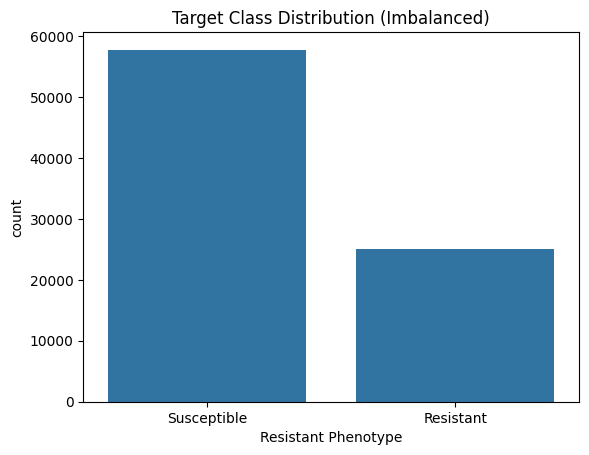

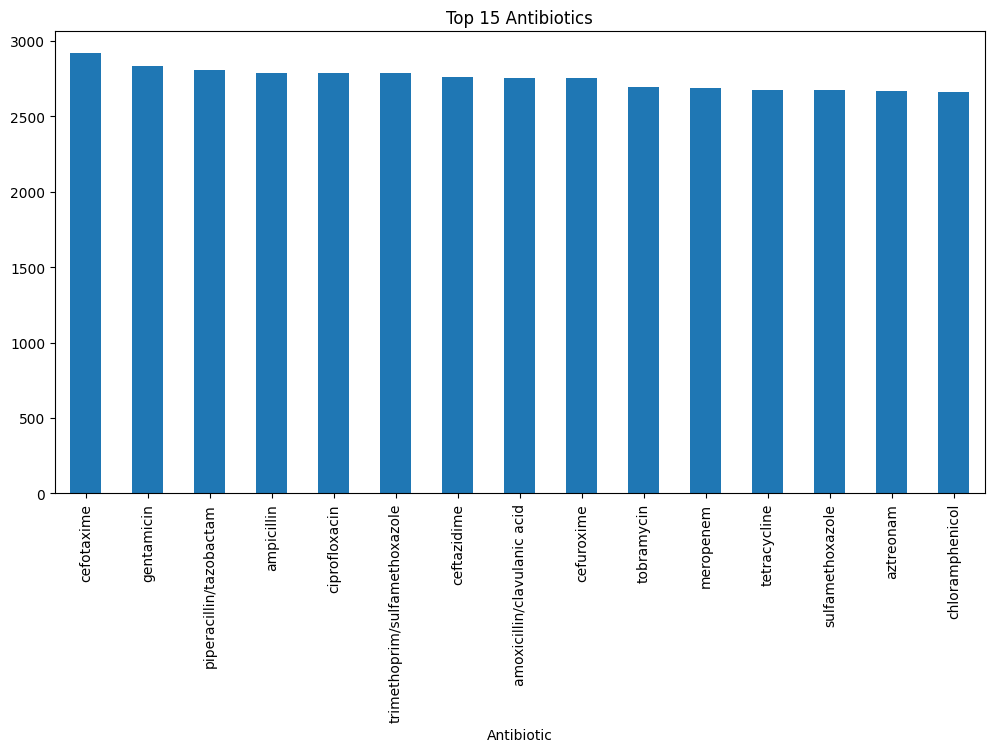

Genus distribution:
 Genus
Escherichia     82884
'Escherichia       13
Name: count, dtype: int64
Most common full bacterium names:
 Genome Name
Escherichia coli strain Fecal samples        476
Escherichia coli Fecal samples               162
Escherichia coli 131                         136
Escherichia coli                             115
Escherichia coli isolate                      82
Escherichia coli strain fhi                   68
Escherichia coli stool                        38
Escherichia coli str. K-12 substr. MG1655     31
Escherichia coli 10                           30
Escherichia coli blood                        29
Name: count, dtype: int64

Evidence types:
 Evidence
Computational Method    79875
Laboratory Method        2937
Name: count, dtype: int64


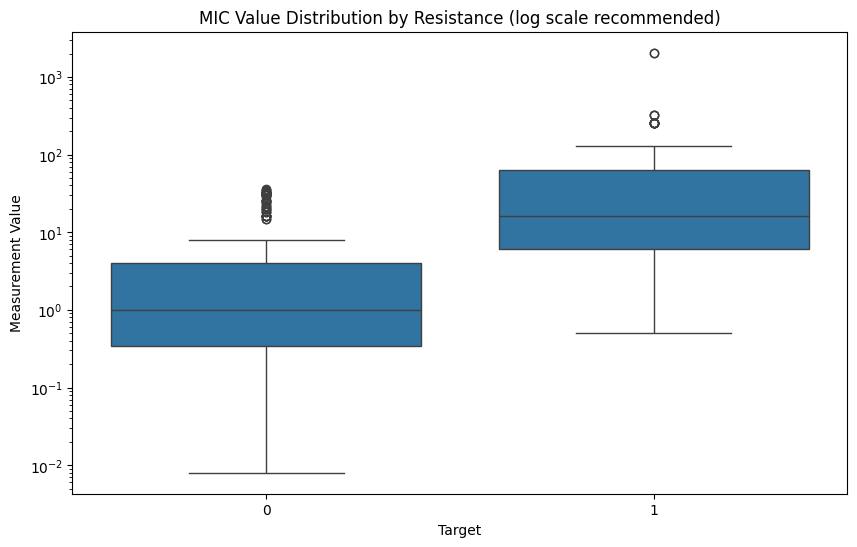

In [6]:
# Class balance
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(data=df, x='Resistant Phenotype')
plt.title('Target Class Distribution (Imbalanced)')
plt.show()

# Top antibiotics
plt.figure(figsize=(12,6))
df['Antibiotic'].value_counts().head(15).plot(kind='bar')
plt.title('Top 15 Antibiotics')
plt.show()

# Bacteria analysis (extract genus/species as per competition guidance)
df['Genus'] = df['Genome Name'].str.split().str[0]
df['Species'] = df['Genome Name'].apply(lambda x: x.split()[1] if len(x.split()) > 1 else np.nan)

print("Genus distribution:\n", df['Genus'].value_counts().head(10))
print("Most common full bacterium names:\n", df['Genome Name'].value_counts().head(10))

# Evidence source
print("\nEvidence types:\n", df['Evidence'].value_counts())

# MIC values (only where available)
plt.figure(figsize=(10,6))
sns.boxplot(data=df[df['Measurement Value'].notna()], x='Target', y='Measurement Value')
plt.title('MIC Value Distribution by Resistance (log scale recommended)')
plt.yscale('log')
plt.show()